<a href="https://colab.research.google.com/github/243Christian/DATA110/blob/main/Christian_Week10_KnowYourData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Getting to know your data

**Christian Tabuku**  
Data 110 · Fall 2026 · Week 10  
Instructor: Rebin Muhammad

[NCbirths.csv from the course GitHub](https://github.com/Reben80/Data110-Fall2026-CRN21802/blob/main/dataset/NCbirths.csv)

To run this in Google Colab, upload the notebook and run the cells from the top. If you upload the course CSV too, keep the name `NCbirths.csv`. The data cell can also read the same file directly from GitHub.

## Setup

pandas holds the tables. matplotlib draws the charts.


In [1]:
import matplotlib.pyplot as plt  # pyplot draws the plots. We call it plt.
import pandas as pd               # pandas holds tables. We call it pd.

# The spines are the four lines that make the frame.
# False hides the top line and the right line.
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## The file

`NCbirths.csv` has one row per birth. There are 1,450 rows and 15 columns. The rows are a sample of births in North Carolina in 2001.

`read_csv` turns the file into a table. It already reads the text `#N/A` as a blank, so `Gained` arrives with missing values. The number `-999` in `Weeks` is kept, because it is a number.


In [2]:
course_csv = "https://raw.githubusercontent.com/Reben80/Data110-Fall2026-CRN21802/main/dataset/NCbirths.csv"
try:
    births = pd.read_csv("NCbirths.csv")
except FileNotFoundError:
    births = pd.read_csv(course_csv)

births.head()

,ID,Plural,Sex,MomAge,Weeks,Marital,RaceMom,HispMom,Gained,Smoke,BirthWeightOz,BirthWeightGm,Low,Premie,MomRace
0,1,1,1,32,40,1,1,N,38.0,0.0,111,3146.85,0,0,white
1,2,1,2,32,37,1,1,N,34.0,0.0,116,3288.60,0,0,white
2,3,1,1,27,39,1,1,N,12.0,0.0,138,3912.30,0,0,white
3,4,1,1,27,39,1,1,N,15.0,0.0,136,3855.60,0,0,white
4,5,1,1,25,39,1,1,N,32.0,0.0,121,3430.35,0,0,white


## 1. How big is the table?

**Exercise.** Print the number of rows and the number of columns.

`shape` is a pair: rows, then columns.

### Your solution

Write your code in the next cell, then run it.


In [3]:
rows, columns = births.shape
print("Rows:", rows)
print("Columns:", columns)

Rows: 1450
Columns: 15


## 2. Where are the blanks?

**Exercise.** Count the missing values in every column.

`isna` is `True` on a blank cell. `sum` counts those `True` values in each column. A blank is not the same thing as a number such as `-999`.

### Your solution

Write your code in the next cell, then run it.


In [4]:
print(births.isna().sum())

ID                0
Plural            0
Sex               0
MomAge            0
Weeks             0
Marital           0
RaceMom           0
HispMom           0
Gained           40
Smoke             5
BirthWeightOz     0
BirthWeightGm     0
Low               0
Premie            0
MomRace           0
dtype: int64


Only two columns have blanks. `Gained` is missing for 40 births and `Smoke` is missing for 5.

## 3. The week that cannot be a gestation

**Exercise.** Show the rows where `Weeks` is below 0, and print how many such rows there are.

A completed pregnancy is not a negative number of weeks. In this file that negative number is `-999`.

### Your solution

Write your code in the next cell, then run it.


In [5]:
negative_weeks = births[births["Weeks"] < 0]
print("Rows with negative weeks:", len(negative_weeks))
negative_weeks

Rows with negative weeks: 1


,ID,Plural,Sex,MomAge,Weeks,Marital,RaceMom,HispMom,Gained,Smoke,BirthWeightOz,BirthWeightGm,Low,Premie,MomRace
1117,1118,1,1,20,-999,2,2,N,NaN,0.0,136,3855.6,0,1,black


## 4. Turn the sentinel into a blank

**Exercise.** On a copy of the table, replace every negative `Weeks` with a missing value. Then print the minimum and the mean of `Weeks`.

`copy` keeps the original `births` table unchanged. `loc` selects the rows. `pd.NA` is a blank. `mean` skips blanks, so the mean changes once `-999` is no longer a number.

### Your solution

Write your code in the next cell, then run it.


In [6]:
births_clean = births.copy()
births_clean.loc[births_clean["Weeks"] < 0, "Weeks"] = pd.NA

print("Minimum weeks:", births_clean["Weeks"].min())
print("Mean weeks:", round(births_clean["Weeks"].mean(), 2))

Minimum weeks: 22.0
Mean weeks: 38.62


The row with ID 1118 uses `-999` for weeks. Leaving it in would pull the average down. After treating it as missing, the shortest recorded pregnancy was 22 weeks and the average was 38.62 weeks.

## 5. Turn the sex code into a word

**Exercise.** Add a column `sex_word`. Code `1` becomes `male` and code `2` becomes `female`. Then count the two words.

`map` looks up each number in a dictionary. Use `{1: "male", 2: "female"}`.

### Your solution

Write your code in the next cell, then run it.


In [7]:
births_clean["sex_word"] = births_clean["Sex"].map({1: "male", 2: "female"})
print(births_clean["sex_word"].value_counts())

sex_word
male      744
female    706
Name: count, dtype: int64


## 6. The shape of the real weeks

**Exercise.** Draw a histogram of `Weeks` after the negative value has been replaced with a blank. Use bins that are one week wide. Label the horizontal axis `completed weeks` and the vertical axis `births`.

Drop the blank before you draw, with `dropna`. One bar per week is `bins` set to a sequence of edges one week apart. The real weeks run from 22 to 45.

### Your solution

Write your code in the next cell, then run it.


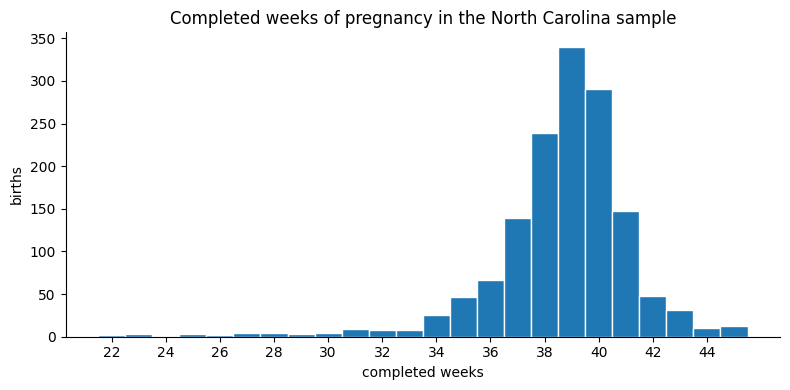

In [8]:
weeks = births_clean["Weeks"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(weeks, bins=range(22, 47), align="left", edgecolor="white")
plt.xticks(range(22, 46, 2))
plt.xlabel("completed weeks")
plt.ylabel("births")
plt.title("Completed weeks of pregnancy in the North Carolina sample")
plt.tight_layout()
plt.show()

Most births in this sample were between 37 and 41 completed weeks. The tallest bar is at 39 weeks.